# Episode 8: Maximum Likelihood, by Hand
<a href="https://colab.research.google.com/github/Kinvecta/how-llms-work/blob/main/Episode%2008%20-%20Maximum%20Likelihood/notebook.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

**Companion notebook** for the series *How Large Language Models Work: From Math to Transformers*. What Learning Means, part 2 of 2.

The episode works every calculation by hand. This notebook does the same calculations in the same order, prints each line the way it appears on screen, and checks every value with an `assert`. It uses only `numpy` and `matplotlib` (both already in Colab), plus Python's built-in `fractions` so the sixths print exactly: choose **Runtime, Run all**.

| Part | What you'll compute | Video numbers |
|---|---|---|
| 1 | Two roads to one number; the likelihood from the chain rule; a second model | 0.18 → 1.715 → 0.857 · model 2: 0.20, loss 0.805 |
| 2 | Underflow, then the four moves: log, the arg max, divide by N, flip the sign | 0.5¹⁰⁰⁰ ≈ 9.33 × 10⁻³⁰² · 0.5¹⁰⁷⁵ = 0 · −1.715 · −1.609 · 0.857 |
| 3 | The Gaussian case with spread τ: the negative log likelihood by hand, three points, and a grid search | 0.919 · 1.419 · line A 3.257 · line B 2.840 |
| 4 | The fine print: four assumptions, the myth, and why dividing by N matters for the gradient | sum 1.715 vs mean 0.857: gradient × N |
| 5 | The check question | 0.1 · 0.768 · 2.919 |
| 6 | Try it yourself, with self-checks | your numbers |

The probabilities 0.30, 0.60, 0.40 and 0.50 are **illustrative** (Episode 7), and so are the three data points. Logs are natural (nats). The noise spread is **τ** (tau): Goodfellow et al. write it with another Greek letter, but this series saves that letter for the sigmoid.

## Setup

In [1]:
from fractions import Fraction as F

import matplotlib.pyplot as plt
import numpy as np

STEEL, GOLD, CORAL, MUTED = "#8FB4E8", "#FFC400", "#FF4D3D", "#8B98AE"   # the video's colours
DOT = "#1B2A4A"                                                          # the data points (white on the video's navy)


def fmt(x):
    """Print a number the way you would write it on paper: 0.18, not 0.18000000000000002."""
    return f"{round(float(x), 8):.10g}"


def surprisal(x):
    """-ln p, in nats (Episode 4)."""
    return -np.log(x)


model1 = np.array([0.30, 0.60])     # Episode 7's two observed words (illustrative)
model2 = np.array([0.40, 0.50])     # Episode 7's check question (illustrative)

## Part 1 · The likelihood

### Step 1: two roads, one number
Episode 7 found the loss by **averaging surprisals**. The cold open takes a different road: **multiply** the probabilities, take minus the log, divide by two.

In [2]:
lik1 = model1.prod()
road1 = surprisal(lik1) / len(model1)
print(f"road 1: {model1[0]:.2f} x {model1[1]:.2f} = {lik1:.2f};  -ln {lik1:.2f} = {surprisal(lik1):.3f};  / 2 = {road1:.3f}")
s1, s2 = surprisal(model1)
road2 = (s1 + s2) / 2
print(f"road 2: ({s1:.3f} + {s2:.3f}) / 2 = {road2:.3f}   (Episode 7: the mean surprisal)")
assert np.isclose(lik1, 0.18) and round(surprisal(lik1), 3) == 1.715 and round(road1, 3) == 0.857
assert round(s1, 3) == 1.204 and round(s2, 3) == 0.511 and round(road2, 3) == 0.857
assert np.isclose(road1, road2)
print("Two roads, one number.")

road 1: 0.30 x 0.60 = 0.18;  -ln 0.18 = 1.715;  / 2 = 0.857
road 2: (1.204 + 0.511) / 2 = 0.857   (Episode 7: the mean surprisal)
Two roads, one number.


### Step 2: what the likelihood asks
Of everything that could have happened, the data are what actually happened. The **likelihood** is how much probability the model gives to that. The data stay fixed; we turn the knobs θ and watch the likelihood change.

For text, Episode 4's **chain rule** does the work. The probability of a whole sequence is exactly the product of each word's probability given the words before it:

**p(x₁, …, x_N) = p(x₁) · p(x₂ | x₁) · … · p(x_N | x₁, …, x_{N−1})**

No independence between the words is needed: each factor already conditions on everything before it. So the likelihood is a product of the very probabilities we have been using. A tiny made-up joint distribution over two words shows the chain rule is exact:

In [3]:
rng = np.random.default_rng(8)
joint = rng.random((4, 4)); joint /= joint.sum()     # any joint distribution over (word 1, word 2)
p_first = joint.sum(axis=1)                           # p(x1)
p_second_given_first = joint / p_first[:, None]       # p(x2 | x1)
for a in range(4):
    for b in range(4):
        assert np.isclose(joint[a, b], p_first[a] * p_second_given_first[a, b])
print("p(x1, x2) = p(x1) p(x2 | x1) for all 16 pairs: the chain rule is exact.")
print(f"\nour two words: Lik = {model1[0]:.2f} x {model1[1]:.2f} = {lik1:.2f}")

p(x1, x2) = p(x1) p(x2 | x1) for all 16 pairs: the chain rule is exact.

our two words: Lik = 0.30 x 0.60 = 0.18


### Step 3: a second model
Model 2 gives the same two words 0.40 and 0.50 (Episode 7's check question).

model 1: Lik = 0.30 x 0.60 = 0.18   loss = 0.857
model 2: Lik = 0.40 x 0.50 = 0.20   loss = 0.805
Higher likelihood, lower loss.


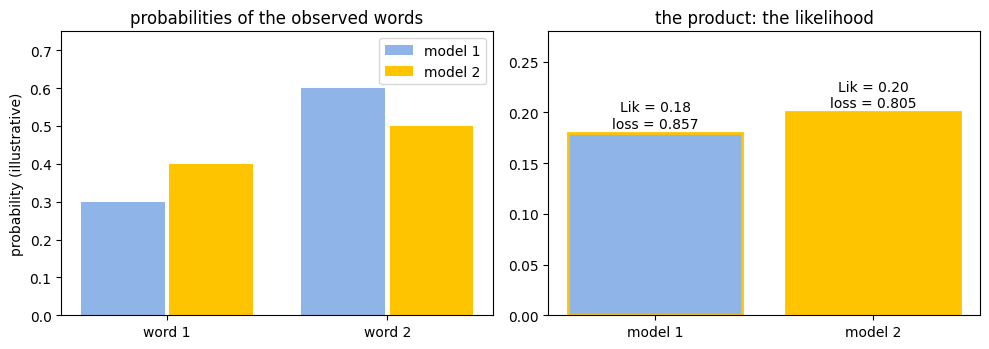

In [4]:
lik2 = model2.prod()
L1, L2 = surprisal(model1).mean(), surprisal(model2).mean()
print(f"model 1: Lik = 0.30 x 0.60 = {lik1:.2f}   loss = {L1:.3f}")
print(f"model 2: Lik = 0.40 x 0.50 = {lik2:.2f}   loss = {L2:.3f}")
assert np.isclose(lik2, 0.20) and lik2 > lik1
assert round(L1, 3) == 0.857 and round(L2, 3) == 0.805 and L2 < L1
print("Higher likelihood, lower loss.")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.6))
xs = np.arange(2)
a1.bar(xs - 0.2, model1, 0.38, color=STEEL, label="model 1")
a1.bar(xs + 0.2, model2, 0.38, color=GOLD, label="model 2")
a1.set_xticks(xs, ["word 1", "word 2"]); a1.set_ylim(0, 0.75); a1.set_ylabel("probability (illustrative)")
a1.set_title("probabilities of the observed words"); a1.legend()
a2.bar(["model 1", "model 2"], [lik1, lik2], color=[STEEL, GOLD], edgecolor=GOLD, linewidth=2)
for k, v in enumerate([lik1, lik2]):
    a2.text(k, v + 0.005, f"Lik = {v:.2f}\nloss = {[L1, L2][k]:.3f}", ha="center")
a2.set_ylim(0, 0.28); a2.set_title("the product: the likelihood")
plt.tight_layout()
plt.show()

## Part 2 · From likelihood to loss in four moves

### Step 4: the problem, products shrink fast
Half times half, a thousand times over. An ordinary computer stores numbers in 64-bit floating point (`float64`), and the smallest positive number it can hold is 2⁻¹⁰⁷⁴.

0.5^1000 = 9.33e-302   (log10 = -301.03: about 10^-301)
0.5^1074 = 4.94e-324   (the smallest positive float64)
0.5^1075 = 0.0   (rounded to zero)

the same thousand halves as a sum of logs: -693.147  (no trouble at all)


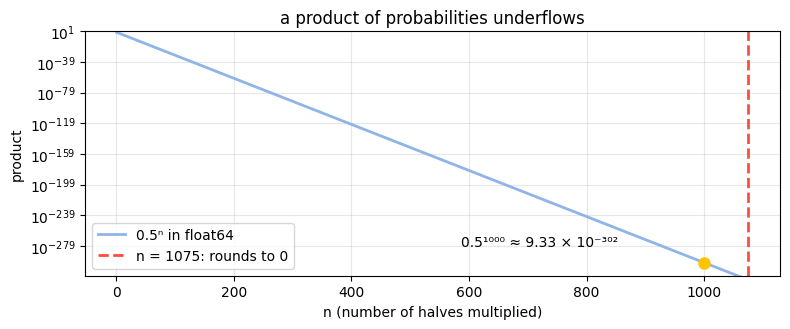

In [5]:
h1000 = 0.5 ** 1000
h1075 = 0.5 ** 1075
print(f"0.5^1000 = {h1000:.3g}   (log10 = {np.log10(h1000):.2f}: about 10^{round(np.log10(h1000))})")
print(f"0.5^1074 = {0.5 ** 1074:.3g}   (the smallest positive float64)")
print(f"0.5^1075 = {h1075}   (rounded to zero)")
assert f"{h1000:.3g}" == "9.33e-302" and round(np.log10(h1000)) == -301
assert h1075 == 0.0 and 0.5 ** 1074 > 0
log_sum = 1000 * np.log(0.5)
print(f"\nthe same thousand halves as a sum of logs: {log_sum:.3f}  (no trouble at all)")
assert np.isfinite(log_sum) and np.isclose(log_sum, np.log(h1000))

ns = np.arange(1, 1101)
vals = 0.5 ** ns.astype(float)
plt.figure(figsize=(8, 3.4))
plt.semilogy(ns[vals > 0], vals[vals > 0], color=STEEL, lw=2, label="0.5ⁿ in float64")
plt.axvline(1075, color=CORAL, lw=2, ls="--", label="n = 1075: rounds to 0")
plt.plot([1000], [h1000], "o", color=GOLD, ms=8)
plt.annotate("0.5¹⁰⁰⁰ ≈ 9.33 × 10⁻³⁰²", (1000, h1000), textcoords="offset points", xytext=(-175, 12))
plt.ylim(1e-318, 10)
plt.xlabel("n (number of halves multiplied)"); plt.ylabel("product")
plt.title("a product of probabilities underflows"); plt.grid(alpha=0.3); plt.legend(loc="lower left")
plt.tight_layout()
plt.show()

### Step 5: move 1, the log turns a product into a sum
**ln(a × b) = ln a + ln b**

In [6]:
la, lb = np.log(0.3), np.log(0.6)
print(f"ln(0.3 x 0.6) = ln 0.3 + ln 0.6 = {la:.3f} + ({lb:.3f}) = {la + lb:.3f}")
print(f"check: ln 0.18 = {np.log(0.18):.3f}")
assert round(la, 3) == -1.204 and round(lb, 3) == -0.511 and round(la + lb, 3) == -1.715
assert np.isclose(np.log(0.3 * 0.6), la + lb)

ln(0.3 x 0.6) = ln 0.3 + ln 0.6 = -1.204 + (-0.511) = -1.715
check: ln 0.18 = -1.715


### Step 6: move 2, the log doesn't change who wins
The log only goes up: bigger input, bigger output. Goodfellow, Bengio and Courville: taking the logarithm "does not change its arg max".

In [7]:
print(f"0.20 > 0.18   and   ln 0.20 = {np.log(0.20):.3f} > ln 0.18 = {np.log(0.18):.3f}")
assert round(np.log(0.20), 3) == -1.609 and round(np.log(0.18), 3) == -1.715 and np.log(0.20) > np.log(0.18)
grid_p = np.linspace(0.001, 1, 1000)
assert np.all(np.diff(np.log(grid_p)) > 0)            # monotonic: it only goes up
liks = rng.random(50)                                 # any 50 likelihoods
assert np.argmax(liks) == np.argmax(np.log(liks))
print("Whichever theta had the biggest likelihood still has the biggest log likelihood.")

0.20 > 0.18   and   ln 0.20 = -1.609 > ln 0.18 = -1.715
Whichever theta had the biggest likelihood still has the biggest log likelihood.


### Step 7: moves 3 and 4, divide by N, then flip the sign
Dividing by N (the number of terms) is just rescaling, so the winner still doesn't change. Flipping the sign makes big become small: the largest log likelihood becomes the smallest loss.

**−(1/N) ln Lik(θ) = (1/N) Σ −ln p_θ(observed token) = L(θ)**

In [8]:
N = 2
logL = np.log(lik1)
mean_log = logL / N
print(f"divide by N = {N}: {logL:.3f} / {N} = {mean_log:.3f}")
print(f"flip the sign:   +{-mean_log:.3f}   <- the loss, mean surprisal (Episode 7)")
assert round(logL, 3) == -1.715 and round(mean_log, 3) == -0.857 and round(-mean_log, 3) == 0.857
assert np.isclose(-mean_log, surprisal(model1).mean())
for M in (model1, model2):                            # the four moves, for both models
    assert np.isclose(-np.log(M.prod()) / len(M), surprisal(M).mean())
assert np.argmax([lik1, lik2]) == np.argmin([L1, L2]) == 1
print("Maximizing the likelihood is exactly the same as minimizing the loss.")
print('Goodfellow et al.: "the negative log-likelihood, equivalently described as the cross-entropy".')

divide by N = 2: -1.715 / 2 = -0.857
flip the sign:   +0.857   <- the loss, mean surprisal (Episode 7)
Maximizing the likelihood is exactly the same as minimizing the loss.
Goodfellow et al.: "the negative log-likelihood, equivalently described as the cross-entropy".


## Part 3 · Numbers: where the square comes from

### Step 8: the assumption and the density
The label y is the prediction ŷ plus noise, and the noise follows a bell curve (a **Gaussian**) with a fixed spread **τ**. The density of y is

**p(y) = 1/√(2πτ²) · e^(−(y − ŷ)²/(2τ²))**

Take minus the log. The log of a product is a sum, and ln e^z = z, so the exponential disappears:

**−ln p(y) = ½ ln(2πτ²) + (y − ŷ)²/(2τ²)**

A constant, plus the squared error over 2τ². The square was hiding inside the bell curve.

In [9]:
def gauss(y, yhat, tau=1.0):
    """The bell-curve density of y around the prediction y-hat, with spread tau."""
    return np.exp(-(y - yhat) ** 2 / (2 * tau ** 2)) / np.sqrt(2 * np.pi * tau ** 2)


def gauss_nll(y, yhat, tau=1.0):
    """-ln p(y): constant + squared error over 2 tau^2."""
    return 0.5 * np.log(2 * np.pi * tau ** 2) + (y - yhat) ** 2 / (2 * tau ** 2)


zs = np.linspace(-12, 12, 24001)
for tau in (0.5, 1.0, 2.0):
    assert np.isclose(gauss(zs, 0, tau).sum() * (zs[1] - zs[0]), 1, atol=1e-6)   # a density: area 1
    for y_, yh in [(2, 2), (5, 6), (4, 11 / 3), (0, 2)]:
        assert np.isclose(-np.log(gauss(y_, yh, tau)), gauss_nll(y_, yh, tau))
print("The bell curve has area 1, and -ln p(y) = constant + (y - y-hat)^2 / (2 tau^2) for every tau tried.")

The bell curve has area 1, and -ln p(y) = constant + (y - y-hat)^2 / (2 tau^2) for every tau tried.


### Step 9: by hand with τ = 1

In [10]:
two_pi = 2 * np.pi
ln_two_pi = np.log(two_pi)
const = 0.5 * ln_two_pi
print(f"2 pi ~ {two_pi:.3f};  ln {two_pi:.3f} ~ {ln_two_pi:.3f};  half of that: {const:.3f}")
missA = gauss_nll(5, 6)
print(f"line A's miss of 1: {const:.3f} + 1^2 / 2 = {const:.3f} + 0.5 = {missA:.3f}")
print(f"a perfect hit pays just the constant: {gauss_nll(2, 2):.3f}")
assert round(two_pi, 3) == 6.283 and round(ln_two_pi, 3) == 1.838 and round(const, 3) == 0.919
assert round(missA, 3) == 1.419 and round(gauss_nll(2, 2), 3) == 0.919

2 pi ~ 6.283;  ln 6.283 ~ 1.838;  half of that: 0.919
line A's miss of 1: 0.919 + 1^2 / 2 = 0.919 + 0.5 = 1.419
a perfect hit pays just the constant: 0.919


### Step 10: all three points, lines A and B
Episode 7's data, (1, 2), (2, 4), (3, 5), and its two lines: A (W = 2, β = 0) and B (W = 1.5, β = 2/3, the least-squares fit).

In [11]:
u = np.array([1, 2, 3])
y = np.array([2, 4, 5])
n_pts = len(u)


def predict(W, beta, x=u):
    """y-hat = W u + beta."""
    return W * x + beta


def total_nll(W, beta, tau=1.0):
    return gauss_nll(y, predict(W, beta), tau).sum()


three_c = n_pts * const
sseA = F(1)                                   # Episode 7: squares 0, 0, 1
sseB = F(1, 36) + F(4, 36) + F(1, 36)         # Episode 7: squares 1/36, 4/36, 1/36
nllA, nllB = total_nll(2, 0), total_nll(1.5, 2 / 3)
print(f"three constants: 3 x {const:.3f} = {three_c:.3f}")
print(f"line A: {three_c:.3f} + 1/2 x {sseA} = {three_c:.3f} + {float(sseA) / 2:.3f} = {nllA:.3f}")
print(f"line B: {three_c:.3f} + 1/2 x {sseB} = {three_c:.3f} + {float(sseB) / 2:.3f} = {nllB:.3f}")
assert np.isclose(float(sseA), ((y - predict(2, 0)) ** 2).sum()) and np.isclose(float(sseB), ((y - predict(1.5, 2 / 3)) ** 2).sum())
assert sseB == F(1, 6) and round(three_c, 3) == 2.757 and round(float(sseB) / 2, 3) == 0.083
assert round(nllA, 3) == 3.257 and round(nllB, 3) == 2.840 and nllB < nllA
assert np.isclose(nllA - nllB, (float(sseA) - float(sseB)) / 2)
print("The constant is identical for both lines: only half the sum of squared errors differs.")

three constants: 3 x 0.919 = 2.757
line A: 2.757 + 1/2 x 1 = 2.757 + 0.500 = 3.257
line B: 2.757 + 1/2 x 1/6 = 2.757 + 0.083 = 2.840
The constant is identical for both lines: only half the sum of squared errors differs.


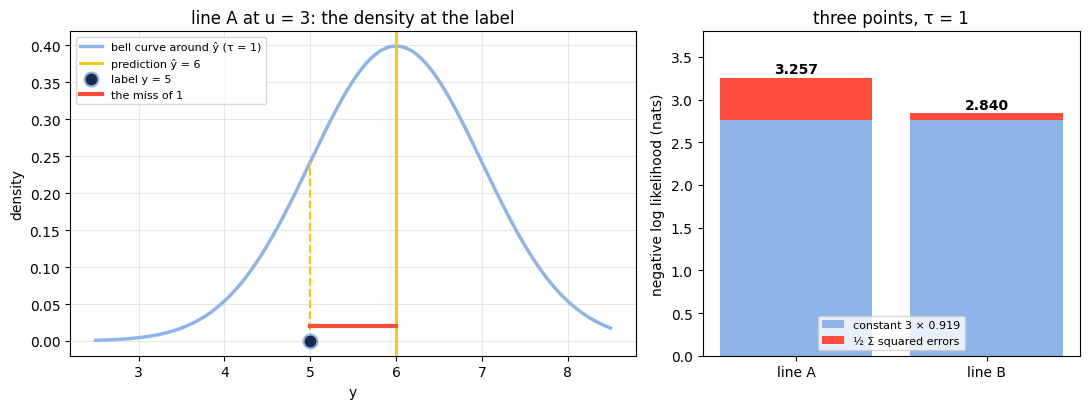

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [3, 2]})
ax = axes[0]
yy = np.linspace(2.5, 8.5, 400)
yhat3 = predict(2, 0)[2]                              # line A at u = 3 predicts 6; the label is 5
ax.plot(yy, gauss(yy, yhat3), color=STEEL, lw=2.5, label="bell curve around ŷ (τ = 1)")
ax.axvline(yhat3, color=GOLD, lw=2, label=f"prediction ŷ = {yhat3}")
ax.plot([5, 5], [0, gauss(5, yhat3)], "--", color=GOLD, lw=1.5)
ax.plot([5], [0], "o", color=DOT, mec=STEEL, mew=1.5, ms=10, label="label y = 5")
ax.plot([5, yhat3], [0.02, 0.02], color=CORAL, lw=3, label="the miss of 1")
ax.set_xlabel("y"); ax.set_ylabel("density"); ax.set_title("line A at u = 3: the density at the label")
ax.legend(loc="upper left", fontsize=8); ax.grid(alpha=0.3)

ax = axes[1]
names = ["line A", "line B"]
ax.bar(names, [three_c, three_c], color=STEEL, label="constant 3 × 0.919")
ax.bar(names, [float(sseA) / 2, float(sseB) / 2], bottom=three_c, color=CORAL, label="½ Σ squared errors")
for k, v in enumerate([nllA, nllB]):
    ax.text(k, v + 0.05, f"{v:.3f}", ha="center", fontweight="bold")
ax.set_ylim(0, 3.8); ax.set_ylabel("negative log likelihood (nats)")
ax.set_title("three points, τ = 1"); ax.legend(loc="lower center", fontsize=8)
plt.tight_layout()
plt.show()

### Step 11: grid search, the lowest loss and the highest likelihood land on the same line
Episode 7's grid of knob settings (W from 0 to 3, β from −2 to 3, in steps of 0.01). For each setting, compute the mean squared error **and** the Gaussian likelihood with τ = 1. The setting with the smallest MSE is the setting with the largest likelihood.

grid of 150,801 settings
lowest MSE:         W = 1.50, beta = 0.67
highest likelihood: W = 1.50, beta = 0.67
Same line: line B, W = 1.5, beta = 2/3 (the grid's nearest beta is 0.67).


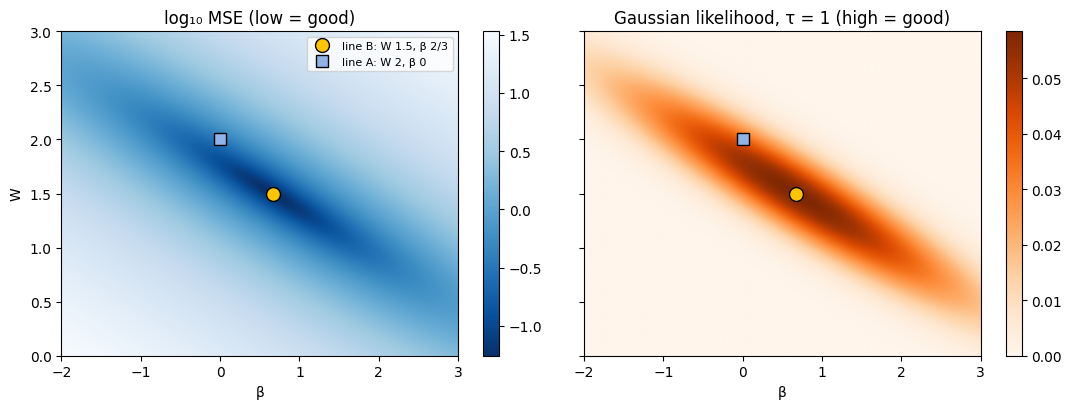

In [13]:
Ws = np.linspace(0, 3, 301)
bs = np.linspace(-2, 3, 501)
WW, BB = np.meshgrid(Ws, bs, indexing="ij")
sq = (y[None, None, :] - (WW[..., None] * u + BB[..., None])) ** 2
mse_grid = sq.mean(axis=-1)
lik_grid = np.exp(-gauss_nll(y[None, None, :], WW[..., None] * u + BB[..., None]).sum(axis=-1))
i1, j1 = np.unravel_index(np.argmin(mse_grid), mse_grid.shape)
i2, j2 = np.unravel_index(np.argmax(lik_grid), lik_grid.shape)
print(f"grid of {mse_grid.size:,} settings")
print(f"lowest MSE:         W = {Ws[i1]:.2f}, beta = {bs[j1]:.2f}")
print(f"highest likelihood: W = {Ws[i2]:.2f}, beta = {bs[j2]:.2f}")
assert (i1, j1) == (i2, j2)
assert np.isclose(Ws[i1], 1.5) and abs(bs[j1] - 2 / 3) <= 0.005
order = np.argsort(mse_grid, axis=None)                # every setting, from lowest MSE up
assert np.all(np.diff(lik_grid.ravel()[order]) <= 1e-12)   # ... has the likelihood going down: the same ranking
print("Same line: line B, W = 1.5, beta = 2/3 (the grid's nearest beta is 0.67).")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
ext = [bs[0], bs[-1], Ws[0], Ws[-1]]
for ax, G, title, cmap in [(axes[0], np.log10(mse_grid), "log₁₀ MSE (low = good)", "Blues_r"),
                           (axes[1], lik_grid, "Gaussian likelihood, τ = 1 (high = good)", "Oranges")]:
    im = ax.imshow(G, origin="lower", extent=ext, aspect="auto", cmap=cmap)
    ax.plot(2 / 3, 1.5, "o", color=GOLD, mec="black", ms=10, label="line B: W 1.5, β 2/3")
    ax.plot(0, 2, "s", color=STEEL, mec="black", ms=8, label="line A: W 2, β 0")
    ax.set_title(title); ax.set_xlabel("β"); fig.colorbar(im, ax=ax)
axes[0].set_ylabel("W"); axes[0].legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()

### Step 12: two losses, one principle

| Output | Assumed distribution | Maximum likelihood gives |
|---|---|---|
| A real number | Gaussian noise, fixed τ | Mean squared error |
| A word from the vocabulary | Categorical (the softmax output) | Cross-entropy |

Goodfellow et al.: a linear output "is often used to produce the mean of a conditional Gaussian distribution". Bishop calls the negative log likelihood "an error function". One principle; only the assumed distribution changes. The cell below checks both rows: the Gaussian negative log likelihood is a constant plus MSE scaled by N/2, and the categorical one with a one-hot target is the cross-entropy.

In [14]:
for W, b in [(2, 0), (1.5, 2 / 3), (1.5, 0.5), (0.7, 1.9)]:
    mse = ((y - predict(W, b)) ** 2).mean()
    assert np.isclose(total_nll(W, b), n_pts * const + n_pts * mse / 2)
p_vocab = np.array([0.30, 0.20, 0.15, 0.35])          # Episode 7: mat, floor, sofa, other (illustrative)
q = np.array([1, 0, 0, 0])                            # the observed word: mat
assert np.isclose(-np.log(p_vocab[q.argmax()]), -(q * np.log(p_vocab)).sum())
print("Gaussian row: NLL = N x 0.919 + (N/2) x MSE.   Categorical row: NLL = cross-entropy = -ln 0.30.")

Gaussian row: NLL = N x 0.919 + (N/2) x MSE.   Categorical row: NLL = cross-entropy = -ln 0.30.


## Part 4 · The fine print

### The four assumptions
1. **Independent training sequences.** The sequences are drawn independently. The words *inside* a sequence need not be: the chain rule (Step 2) is exact.
2. **A fixed family of models.** θ ranges over one family. If the truth lies outside it, the best you get is the closest member, measured in cross-entropy, not the truth.
3. **The training sample.** The fit is made on the training data.
4. **For squared error, τ is fixed.** With τ fixed, the constant ½ ln(2πτ²) and the factor 1/(2τ²) don't depend on W and β. If τ is learned too, the term N ln τ stays in the loss, and the loss is no longer just squared error. The best line doesn't move: for every τ, the W and β that minimize the loss are still the least-squares ones, and the best τ² comes out as the mean squared error.

### The myth: "a low training loss means a good model"
It's tempting: low loss means high likelihood. But the loss is averaged over the **training** data. A model can memorize those and still stumble on text it has never seen. Whether it generalizes is a separate question: Episode 11.

### Step 13: why dividing by N matters for the gradient
Dividing by N doesn't change which θ wins, but it scales the loss, and so its gradient (Episode 6's slope), by 1/N. Here the loss is written as a function of the two probabilities, so its gradient is easy to write down: the slope of −ln p is −1/p.

In [15]:
probs = model1.copy()
loss_sum, loss_mean = surprisal(probs).sum(), surprisal(probs).mean()
grad_sum = -1 / probs                                 # d/dp of sum of -ln p
grad_mean = grad_sum / len(probs)                     # d/dp of the mean
print(f"sum:  {loss_sum:.3f}   gradient {np.round(grad_sum, 3)}")
print(f"mean: {loss_mean:.3f}   gradient {np.round(grad_mean, 3)}")
print(f"the sum's gradient is {fmt((grad_sum / grad_mean)[0])} times bigger (N = {len(probs)})")
assert round(loss_sum, 3) == 1.715 and round(loss_mean, 3) == 0.857
assert np.allclose(grad_sum / grad_mean, len(probs))
eps = 1e-6                                            # check the slopes numerically
for k in range(2):
    d = np.zeros(2); d[k] = eps
    assert np.isclose((surprisal(probs + d).sum() - surprisal(probs - d).sum()) / (2 * eps), grad_sum[k])

# the same factor for the three dots and line A's knobs (W, beta): factor N = 3
def grad_sse(W, b):
    r = y - predict(W, b)
    return np.array([-2 * (r * u).sum(), -2 * r.sum()])


gS = grad_sse(2, 0)
gM = gS / n_pts
print(f"line A: gradient of the sum of squared errors {gS}, of the mean {np.round(gM, 3)}: factor {fmt(gS[0] / gM[0])}")
assert np.allclose(gS / gM, n_pts) and np.allclose(gS, [6, 2])
print("With millions of words, the sum would be millions of times bigger: the step size eta is set against the mean (Episodes 9 and 10).")

sum:  1.715   gradient [-3.333 -1.667]
mean: 0.857   gradient [-1.667 -0.833]
the sum's gradient is 2 times bigger (N = 2)
line A: gradient of the sum of squared errors [6 2], of the mean [2.    0.667]: factor 3
With millions of words, the sum would be millions of times bigger: the step size eta is set against the mean (Episodes 9 and 10).


## Part 5 · Check question
A batch has three words, and the model gives the observed words probabilities 0.5, 0.25 and 0.8. (1) What's the likelihood? (2) What's the mean loss L? (3) With τ = 1, what does a prediction that misses by two pay in negative log likelihood?

In [16]:
cq = np.array([0.5, 0.25, 0.8])
step = cq[0] * cq[1]
likc = step * cq[2]
Lc = surprisal(likc) / len(cq)
miss2 = gauss_nll(2, 0)
print(f"(1) 0.5 x 0.25 = {fmt(step)};  x 0.8 = {fmt(likc)}")
print(f"(2) -ln {fmt(likc)} = {surprisal(likc):.3f};  / {len(cq)} = {Lc:.3f} nats")
print(f"(3) {const:.3f} + 2^2 / 2 = {const:.3f} + {fmt(2 ** 2 / 2)} = {miss2:.3f}")
assert np.isclose(step, 0.125) and np.isclose(likc, 0.1)
assert round(surprisal(likc), 3) == 2.303 and round(Lc, 3) == 0.768 and np.isclose(Lc, surprisal(cq).mean())
assert round(miss2, 3) == 2.919

(1) 0.5 x 0.25 = 0.125;  x 0.8 = 0.1
(2) -ln 0.1 = 2.303;  / 3 = 0.768 nats
(3) 0.919 + 2^2 / 2 = 0.919 + 2 = 2.919


## Part 6 · Try it yourself
Change the values in the next cells and re-run them. The self-checks tell you whether your own hand calculation matches.

1. Multiply three probabilities, then add their logs, and check you get the same answer both ways.
2. Run the grid search with your own τ and watch the lowest loss and the highest likelihood land on the same line.
3. Work out the Gaussian negative log likelihood (τ = 1) for line C from Episode 7: W = 1.5, β = 1/2. The cell keeps the answer hidden until you enter yours.

In [17]:
my_probs = [0.5, 0.25, 0.8]            # 1. any three probabilities
my_product, my_log_sum = None, None    #    your hand answers: the product, and ln a + ln b + ln c

prod = np.prod(my_probs)
log_sum = np.sum(np.log(my_probs))
print(" x ".join(fmt(pk) for pk in my_probs) + f" = {prod:.4g};   ln of that = {np.log(prod):.3f}")
print(" + ".join(f"({np.log(pk):.3f})" for pk in my_probs) + f" = {log_sum:.3f}")
print("(the terms are printed rounded; the sum uses the unrounded values)")
if my_product is not None:
    print("product: matches" if np.isclose(my_product, prod, atol=1e-3) else f"product: not quite, {prod:.4g}")
if my_log_sum is not None:
    print("log sum: matches" if np.isclose(my_log_sum, log_sum, atol=1e-3) else f"log sum: not quite, {log_sum:.3f}")
assert all(0 < pk <= 1 for pk in my_probs) and np.isclose(np.log(prod), log_sum)
print("Same answer both ways: the log turns the product into a sum.")

0.5 x 0.25 x 0.8 = 0.1;   ln of that = -2.303
(-0.693) + (-1.386) + (-0.223) = -2.303
(the terms are printed rounded; the sum uses the unrounded values)
Same answer both ways: the log turns the product into a sum.


In [18]:
my_tau = 1.0                           # 2. try 0.5, 2, 10: the spread changes the likelihood, not the winner

# compare the summed NLL (minus log likelihood) instead of exp(-NLL): for a tiny tau, exp(-NLL) underflows to 0 (Step 4!)
nll_tau = gauss_nll(y[None, None, :], WW[..., None] * u + BB[..., None], my_tau).sum(axis=-1)
i3, j3 = np.unravel_index(np.argmin(nll_tau), nll_tau.shape)
print(f"tau = {fmt(my_tau)}: highest likelihood at W = {Ws[i3]:.2f}, beta = {bs[j3]:.2f}")
print(f"lowest MSE (any tau): W = {Ws[i1]:.2f}, beta = {bs[j1]:.2f}")
assert my_tau > 0 and (i3, j3) == (i1, j1)
print("Same line.")

tau = 1: highest likelihood at W = 1.50, beta = 0.67
lowest MSE (any tau): W = 1.50, beta = 0.67
Same line.


In [19]:
my_nll_C = None                        # 3. your hand answer for line C, tau = 1 (three decimals)
show_answer = False                    #    set True to see the worked answer

nll_C = total_nll(1.5, 0.5)
errs_C = y - predict(1.5, 0.5)
if my_nll_C is None:
    print("Enter your answer in my_nll_C. Hint: line C's errors are 0, 1/2 and 0 (Episode 7).")
elif np.isclose(my_nll_C, nll_C, atol=0.0015):
    print("your answer matches")
else:
    print("not quite: three constants, plus half the sum of squared errors")
if show_answer:
    print(f"3 x {const:.3f} + 1/2 x {F(float((errs_C ** 2).sum())).limit_denominator()} = {three_c:.3f} + {((errs_C ** 2).sum()) / 2:.3f} = {nll_C:.3f}")
assert np.allclose(errs_C, [0, 0.5, 0]) and np.isclose(nll_C - nllB, 1 / 8 - 1 / 12)   # checked without printing the answer
assert nllB < nll_C < nllA                    # between lines B and A, as its MSE is (Episode 7)

Enter your answer in my_nll_C. Hint: line C's errors are 0, 1/2 and 0 (Episode 7).


In [20]:
print("All Episode 8 checks passed.")

All Episode 8 checks passed.
